## Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import Cloud95Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import matplotlib.pyplot as plt
import numpy as np

## Visualize images and masks

Total number of patches: 34701


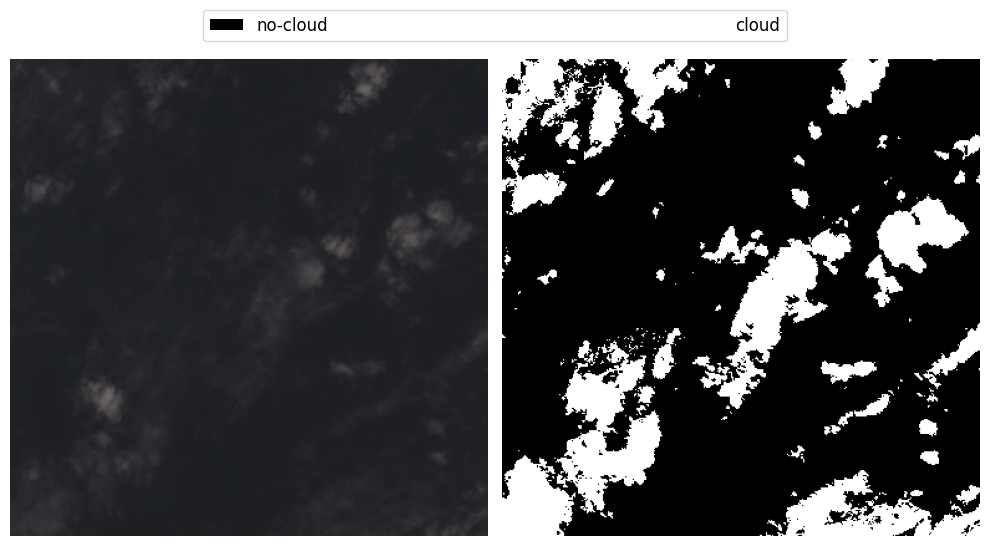

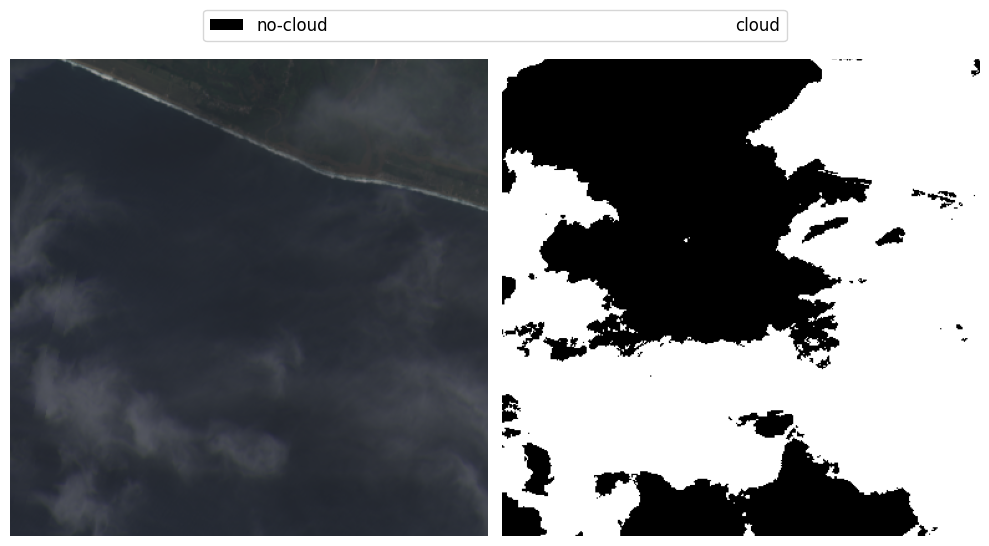

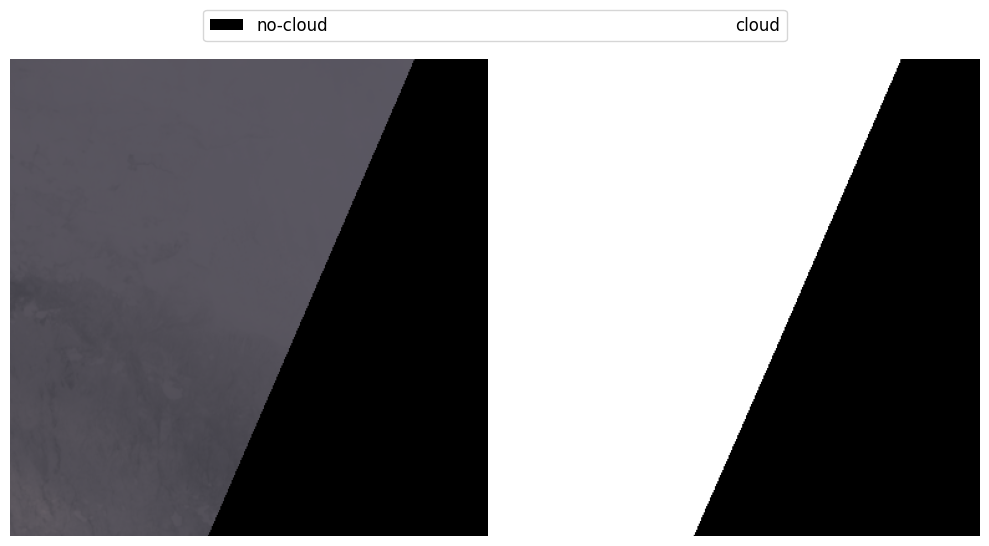

In [28]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/95cloud/train",
    "selection": "rgb"
}
dataset = Cloud95Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(4);
dataset.show_image(5);
dataset.show_image(6);

In [29]:
dataset.data_distribution_table()

,Number of pixels
no-cloud,3.677827e+09
cloud,1.439043e+09


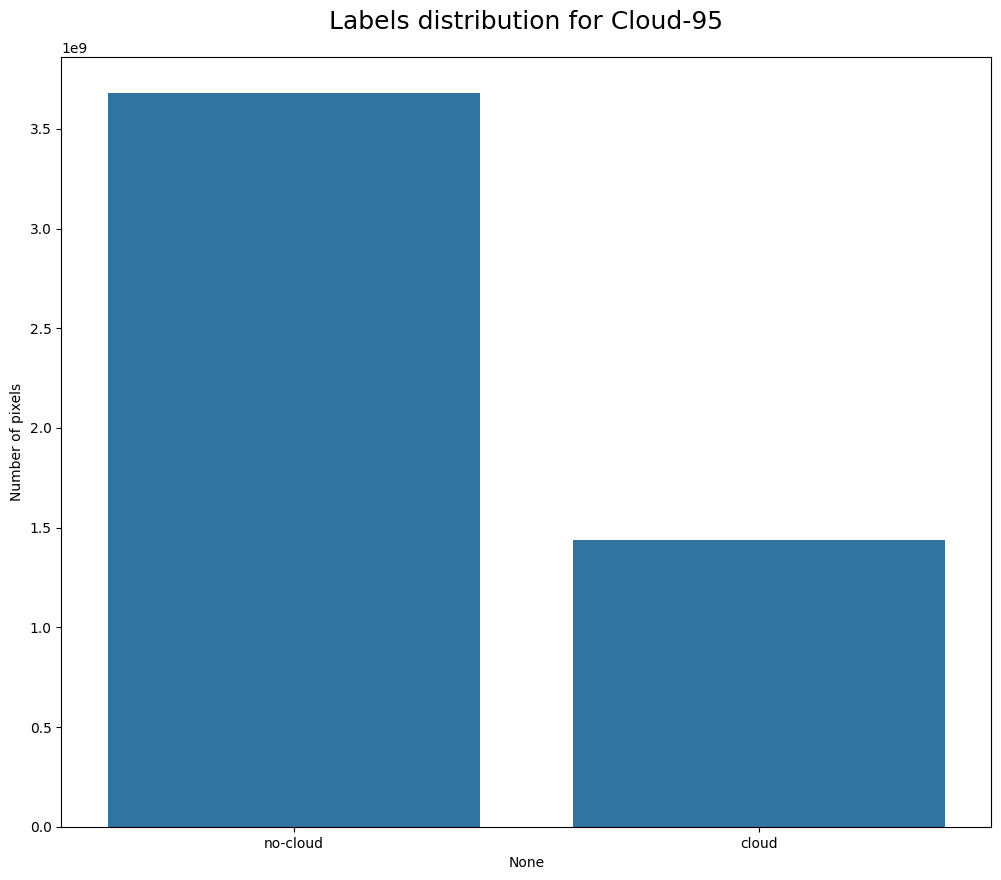

In [30]:
dataset.data_distribution_barchart();

## Load training data

In [32]:
train_dataset_config = {
    "batch_size": 15,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/95cloud/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = Cloud95Dataset(train_dataset_config)
len(train_dataset)

34701

## Create the model

In [33]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/95cloud"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [34]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-07-28 09:39:36,103 INFO Starting training.
training: 100%|██████████| 2314/2314 [1:03:37<00:00,  1.65s/it]
2025-07-28 10:43:13,586 INFO epoch: 1, time: 3817, loss:  0.29971
testing on train set: 100%|██████████| 2314/2314 [1:03:06<00:00,  1.64s/it]
2025-07-28 11:46:22,164 INFO IOU:0.5613263876075372, IOU mean:0.372636993666367, IOU per Class:[0.70974589 0.0355281 ]
training: 100%|██████████| 2314/2314 [1:04:28<00:00,  1.67s/it]
2025-07-28 12:50:50,453 INFO epoch: 2, time: 3868, loss:  0.27747
testing on train set: 100%|██████████| 2314/2314 [1:05:44<00:00,  1.70s/it]
2025-07-28 13:56:34,538 INFO IOU:0.5620145514987536, IOU mean:0.3829094580421758, IOU per Class:[0.70975861 0.0560603 ]
training: 100%|██████████| 2314/2314 [1:02:39<00:00,  1.62s/it]
2025-07-28 14:59:13,970 INFO epoch: 3, time: 3759, loss:  0.27643
testing on train set: 100%|██████████| 2314/2314 [1:02:24<00:00,  1.62s/it]
2025-07-28 16:01:38,869 INFO IOU:0.5623179539585195, IOU mean:0.37760488176057466, IOU per Clas

## Predictions

2025-07-29 07:28:58,809 INFO Loading checkpoint /home/dragik/data/FAIR_EO/95cloud/checkpoint.pth.tar
2025-07-29 07:29:00,283 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/95cloud/checkpoint.pth.tar at epoch 11


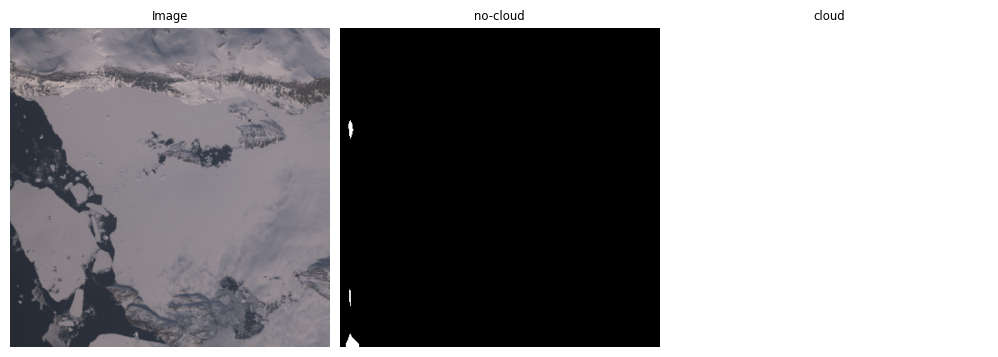

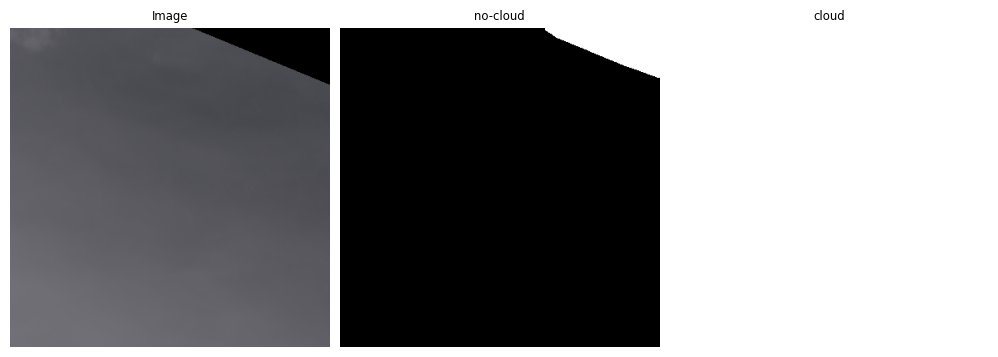

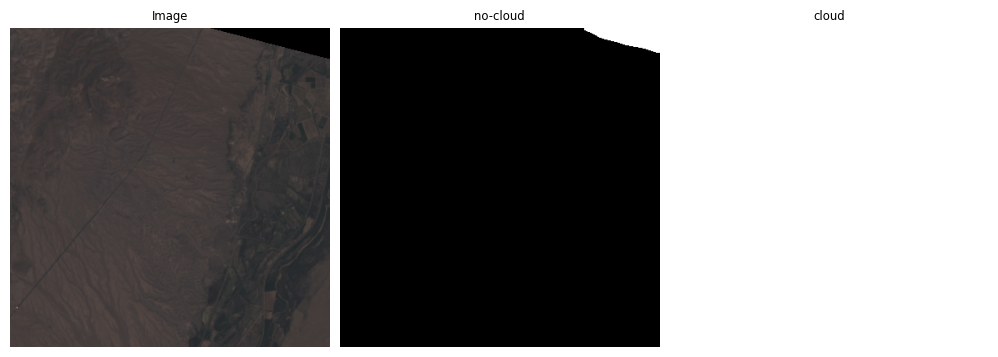

In [40]:
model_path = "/home/dragik/data/FAIR_EO/95cloud/checkpoint.pth.tar"
labels = ["no-cloud","cloud"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})

imageB01 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/red/red_patch_59_3_by_11_LC08_L1TP_018008_20160520_20170324_01_T1.TIF')
imageB02 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/green/green_patch_59_3_by_11_LC08_L1TP_018008_20160520_20170324_01_T1.TIF')
imageB03 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/blue/blue_patch_59_3_by_11_LC08_L1TP_018008_20160520_20170324_01_T1.TIF')
image = np.dstack((imageB01,imageB02,imageB03))/50000
fig = model.predict_masks(image, labels, transform)

imageB01 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/red/red_patch_103_5_by_15_LC08_L1TP_066014_20160520_20170223_01_T1.TIF')
imageB02 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/green/green_patch_103_5_by_15_LC08_L1TP_066014_20160520_20170223_01_T1.TIF')
imageB03 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/blue/blue_patch_103_5_by_15_LC08_L1TP_066014_20160520_20170223_01_T1.TIF')
image = np.dstack((imageB01,imageB02,imageB03))/50000
fig = model.predict_masks(image, labels, transform)

imageB01 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/red/red_patch_103_5_by_19_LC08_L1TP_034037_20160520_20170223_01_T1.TIF')
imageB02 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/green/green_patch_103_5_by_19_LC08_L1TP_034037_20160520_20170223_01_T1.TIF')
imageB03 = image_loader('/home/dragik/data/FAIR_EO/95cloud/test/images/blue/blue_patch_103_5_by_19_LC08_L1TP_034037_20160520_20170223_01_T1.TIF')
image = np.dstack((imageB01,imageB02,imageB03))/50000
fig = model.predict_masks(image, labels, transform)